In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("plastic_new.csv")

In [46]:
df.head()

,melt_temp,mold_temp,time_to_fill,zdx_plast_time,zux_cycle_time,skx_closing_force,sks_clamp_peak,ms_torque_peak,mm_torque_mean,apss_back_press_peak,apvs_inj_press_peak,cpn_screw_pos_hold,svo_shot_vol,quality
0,106.476184,80.617,7.124,3.16,74.83,886.900000,904.000000,116.9,104.300000,145.6,922.3,8.82,18.73,1.0
1,105.505000,81.362,6.968,3.16,74.81,919.409791,935.900000,113.9,104.900000,145.6,930.5,8.59,18.73,1.0
2,105.505000,80.411,6.864,4.08,74.81,908.600000,902.344823,120.5,106.503496,147.0,933.1,8.80,18.98,1.0
3,106.474827,81.162,6.864,3.16,74.82,879.410871,902.033653,127.3,104.900000,145.6,922.3,8.85,18.73,1.0
4,106.466140,81.471,6.864,3.22,74.83,885.644260,902.821269,120.5,106.700000,145.6,917.5,8.80,18.75,1.0


In [47]:
X=df.drop(columns="quality")

In [48]:
X

,melt_temp,mold_temp,time_to_fill,zdx_plast_time,zux_cycle_time,skx_closing_force,sks_clamp_peak,ms_torque_peak,mm_torque_mean,apss_back_press_peak,apvs_inj_press_peak,cpn_screw_pos_hold,svo_shot_vol
0,106.476184,80.617,7.124,3.16,74.83,886.900000,904.000000,116.9,104.300000,145.6,922.3,8.82,18.73
1,105.505000,81.362,6.968,3.16,74.81,919.409791,935.900000,113.9,104.900000,145.6,930.5,8.59,18.73
2,105.505000,80.411,6.864,4.08,74.81,908.600000,902.344823,120.5,106.503496,147.0,933.1,8.80,18.98
3,106.474827,81.162,6.864,3.16,74.82,879.410871,902.033653,127.3,104.900000,145.6,922.3,8.85,18.73
4,106.466140,81.471,6.864,3.22,74.83,885.644260,902.821269,120.5,106.700000,145.6,917.5,8.80,18.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1446,106.072000,81.493,6.188,2.87,75.65,905.500000,920.800000,114.5,107.500000,145.5,907.3,8.96,18.61
1447,106.026000,81.456,6.084,2.87,75.63,906.800000,922.500000,122.3,106.600000,144.9,905.6,8.92,18.65
1448,106.064000,81.420,6.188,2.84,75.66,905.900000,922.100000,125.2,110.700000,147.5,921.6,8.97,18.60
1449,106.131000,81.401,6.188,2.89,75.67,907.200000,921.500000,120.8,106.900000,145.4,895.5,8.93,18.63


In [49]:
y=df["quality"].astype(int)

In [50]:
y

0       1
1       1
2       1
3       1
4       1
       ..
1446    4
1447    4
1448    4
1449    4
1450    4
Name: quality, Length: 1451, dtype: int64

In [51]:
y.value_counts()

quality
2    406
1    370
4    365
3    310
Name: count, dtype: int64

1 = "waste"  

2 = "acceptable"  

3 = "target"  

4 = "inefficient"  

In [52]:
from sklearn.model_selection import train_test_split
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=31)

In [53]:
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=31)

In [54]:
len(X_train), len(X_val), len(X_test)

(870, 290, 291)

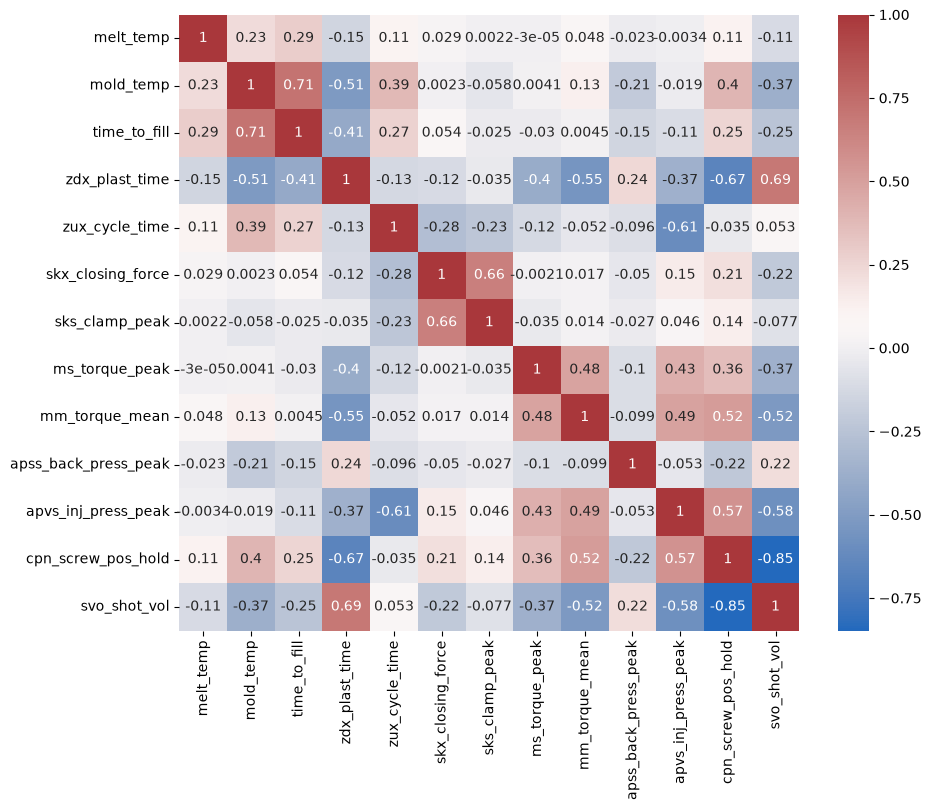

In [55]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(X_train.corr(), annot=True, cmap="vlag")
plt.show()

In [56]:
from sklearn.neighbors import KNeighborsClassifier

In [57]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
A_train=scaler.fit_transform(X_train)
A_val=scaler.transform(X_val)

In [58]:
model_all=KNeighborsClassifier(n_neighbors=5)
model_all.fit(A_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [59]:
from sklearn.metrics import balanced_accuracy_score, classification_report


In [60]:
pred_all=model_all.predict(A_val)
balanced_accuracy_score(y_val, pred_all)

0.88690330852284

In [61]:
from sklearn.feature_selection import SelectKBest, f_classif
selector=SelectKBest(score_func=f_classif, k=5)
S_train=selector.fit_transform(A_train, y_train)
S_val=selector.transform(A_val)

In [62]:
S_train


array([[-0.22039283, -0.73341715,  0.40909927,  1.18062348, -0.47007804],
       [ 1.49350003,  2.120137  , -0.7399707 ,  0.92570918, -0.53560294],
       [-0.05173848, -0.73341715,  0.1671898 ,  1.27331959, -0.23110487],
       ...,
       [ 0.06449627, -0.30841973,  0.10671244, -0.90503901,  0.08881083],
       [-1.07961838, -0.70306019,  2.70723921,  1.20379751, -3.55360284],
       [-0.07452961, -0.30841973, -0.0142423 , -0.97456109,  0.69009817]],
      shape=(870, 5))

In [63]:
X.columns[selector.get_support()]

Index(['mold_temp', 'time_to_fill', 'zdx_plast_time', 'zux_cycle_time',
       'apvs_inj_press_peak'],
      dtype='str')

In [64]:
pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)

zux_cycle_time          6655.066258
apvs_inj_press_peak      220.424675
mold_temp                219.799154
time_to_fill             188.277691
zdx_plast_time           158.594984
cpn_screw_pos_hold       139.632446
svo_shot_vol             138.211518
skx_closing_force         96.476682
sks_clamp_peak            59.791842
apss_back_press_peak      23.999273
melt_temp                 15.744756
mm_torque_mean            12.770032
ms_torque_peak             7.615973
dtype: float64

In [65]:
model_selected=KNeighborsClassifier(n_neighbors=5)
model_selected.fit(S_train, y_train)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [66]:
pred_selected=model_selected.predict(S_val)
balanced_accuracy_score(y_val, pred_selected)

0.9067416952967108

In [69]:
import plotly.express as px
px.scatter(df, x="zux_cycle_time", y="apvs_inj_press_peak", color="quality")

In [86]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
Z_train=pca.fit_transform(A_train)
Z_val=pca.transform(A_val)
Z_train

array([[ 0.66683399,  0.53589608],
       [-1.16711473,  2.72021416],
       [ 1.0570013 ,  0.51818188],
       ...,
       [ 0.52321139, -0.64926681],
       [ 6.86540852,  1.52901431],
       [ 0.41632957, -0.22618057]], shape=(870, 2))

In [87]:
pd.Series(pca.components_[0], index=X.columns)

melt_temp              -0.096714
mold_temp              -0.252555
time_to_fill           -0.189959
zdx_plast_time          0.419861
zux_cycle_time          0.033324
skx_closing_force      -0.119772
sks_clamp_peak         -0.062682
ms_torque_peak         -0.263981
mm_torque_mean         -0.338721
apss_back_press_peak    0.149918
apvs_inj_press_peak    -0.317096
cpn_screw_pos_hold     -0.439178
svo_shot_vol            0.441349
dtype: float64

<Axes: >

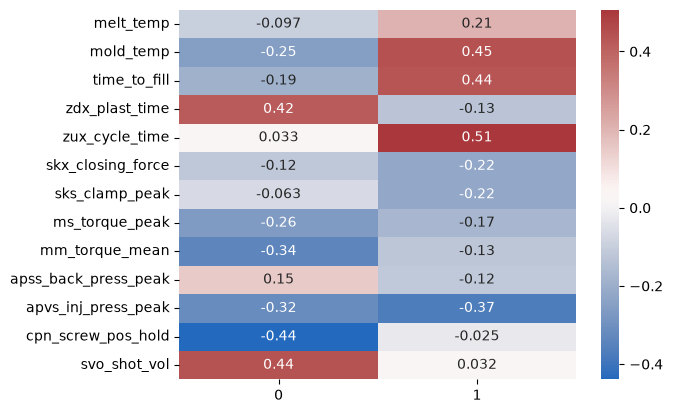

In [88]:
weight_table=pd.DataFrame(pca.components_.T,index=X.columns)
sns.heatmap(weight_table, annot=True, cmap="vlag")

In [89]:
model_pca=KNeighborsClassifier(n_neighbors=5)

In [90]:
model_pca.fit(Z_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [91]:
pred_pca=model_pca.predict(Z_val)
balanced_accuracy_score(y_val, pred_pca)

0.8079480091374331

In [92]:
Z_train

array([[ 0.66683399,  0.53589608],
       [-1.16711473,  2.72021416],
       [ 1.0570013 ,  0.51818188],
       ...,
       [ 0.52321139, -0.64926681],
       [ 6.86540852,  1.52901431],
       [ 0.41632957, -0.22618057]], shape=(870, 2))

In [93]:
px.scatter(x=Z_train[:,0], y=Z_train[:,1], color=y_train.astype(str), labels={"x":"PC1", "y":"PC2", "color":"Quality"})